# Biodiversity in National Parks

Nama: Rolin  
Tanggal: 19 September

## Ringkasan Proyek

Saya ingin melihat bagaimana status konservasi spesies di beberapa taman nasional,
lalu mencari tahu kategori spesies apa yang paling sering masuk daftar dilindungi.

Data yang dipakai ada dua: `species_info.csv` yang berisi data spesies beserta
status konservasinya, dan `observations.csv` yang mencatat berapa kali tiap spesies
terlihat di tiap taman selama 7 hari pengamatan.

Alur kerjanya: muat data, cek sekilas, bersihkan nilai kosong, hitung proporsi
spesies dilindungi per kategori, uji chi-square, lalu lihat sebaran observasi
per taman, dan terakhir kesimpulan.


## 1. Memuat Data


In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline


In [45]:
species = pd.read_csv("species_info.csv")
observations = pd.read_csv("observations.csv")


In [46]:
species.head()


,category,scientific_name,common_names,conservation_status
0,Mammal,Clethrionomys gapperi gapperi,Gapper's Red-Backed Vole,NaN
1,Mammal,Bos bison,"American Bison, Bison",NaN
2,Mammal,Bos taurus,"Aurochs, Aurochs, Domestic Cattle (Feral), Dom...",NaN
3,Mammal,Ovis aries,"Domestic Sheep, Mouflon, Red Sheep, Sheep (Feral)",NaN
4,Mammal,Cervus elaphus,Wapiti Or Elk,NaN


In [47]:
observations.head()


,scientific_name,park_name,observations
0,Vicia benghalensis,Great Smoky Mountains National Park,68
1,Neovison vison,Great Smoky Mountains National Park,77
2,Prunus subcordata,Yosemite National Park,138
3,Abutilon theophrasti,Bryce National Park,84
4,Githopsis specularioides,Great Smoky Mountains National Park,85


In [48]:
print(species.shape)
print(observations.shape)


(5824, 4)
(23296, 3)


In [49]:
species.info()


<class 'pandas.DataFrame'>
RangeIndex: 5824 entries, 0 to 5823
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   category             5824 non-null   str  
 1   scientific_name      5824 non-null   str  
 2   common_names         5824 non-null   str  
 3   conservation_status  191 non-null    str  
dtypes: str(4)
memory usage: 182.1 KB


In [50]:
observations.info()


<class 'pandas.DataFrame'>
RangeIndex: 23296 entries, 0 to 23295
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   scientific_name  23296 non-null  str  
 1   park_name        23296 non-null  str  
 2   observations     23296 non-null  int64
dtypes: int64(1), str(2)
memory usage: 546.1 KB


Tabel `species_info` memuat kategori tiap spesies, nama ilmiah, nama umum, dan
status konservasinya. Sementara `observations` mencatat jumlah kemunculan tiap
spesies di masing-masing taman nasional.


## 2. Eksplorasi Data


In [51]:
species.describe()


,category,scientific_name,common_names,conservation_status
count,5824,5824,5824,191
unique,7,5541,5504,4
top,Vascular Plant,Canis lupus,Dicranum Moss,Species of Concern
freq,4470,3,7,161


In [52]:
species.category.value_counts()


category
Vascular Plant       4470
Bird                  521
Nonvascular Plant     333
Mammal                214
Fish                  127
Amphibian              80
Reptile                79
Name: count, dtype: int64

In [53]:
observations.park_name.value_counts()


park_name
Great Smoky Mountains National Park    5824
Yosemite National Park                 5824
Bryce National Park                    5824
Yellowstone National Park              5824
Name: count, dtype: int64

In [54]:
species.conservation_status.value_counts(dropna=False)


conservation_status
NaN                   5633
Species of Concern     161
Endangered              16
Threatened              10
In Recovery              4
Name: count, dtype: int64

Ada cukup banyak nilai kosong di kolom `conservation_status`. Nilai kosong ini
sebenarnya berarti spesies tersebut tidak masuk program konservasi apa pun.
Agar lebih mudah dihitung, saya isi dengan label "No Intervention".


In [55]:
species.fillna({"conservation_status": "No Intervention"}, inplace=True)
species.conservation_status.value_counts()


conservation_status
No Intervention       5633
Species of Concern     161
Endangered              16
Threatened              10
In Recovery              4
Name: count, dtype: int64

In [56]:
protected = species[species.conservation_status != "No Intervention"]
protected.shape


(191, 4)

In [57]:
protected.groupby(["category", "conservation_status"]).size()


category           conservation_status
Amphibian          Endangered              1
                   Species of Concern      4
                   Threatened              2
Bird               Endangered              4
                   In Recovery             3
                   Species of Concern     72
Fish               Endangered              3
                   Species of Concern      4
                   Threatened              4
Mammal             Endangered              7
                   In Recovery             1
                   Species of Concern     28
                   Threatened              2
Nonvascular Plant  Species of Concern      5
Reptile            Species of Concern      5
Vascular Plant     Endangered              1
                   Species of Concern     43
                   Threatened              2
dtype: int64

### Proporsi spesies dilindungi per kategori


In [58]:
total = species.groupby("category").scientific_name.nunique()
prot = protected.groupby("category").scientific_name.nunique()

prop = pd.DataFrame({"total": total, "protected": prot})
prop.fillna(0, inplace=True)
prop["proportion"] = prop["protected"] / prop["total"]
prop.sort_values("proportion", ascending=False)


,total,protected,proportion
category,,,
Mammal,176,30,0.170455
Bird,488,75,0.153689
Amphibian,79,7,0.088608
Fish,125,11,0.088000
Reptile,78,5,0.064103
Nonvascular Plant,333,5,0.015015
Vascular Plant,4262,46,0.010793


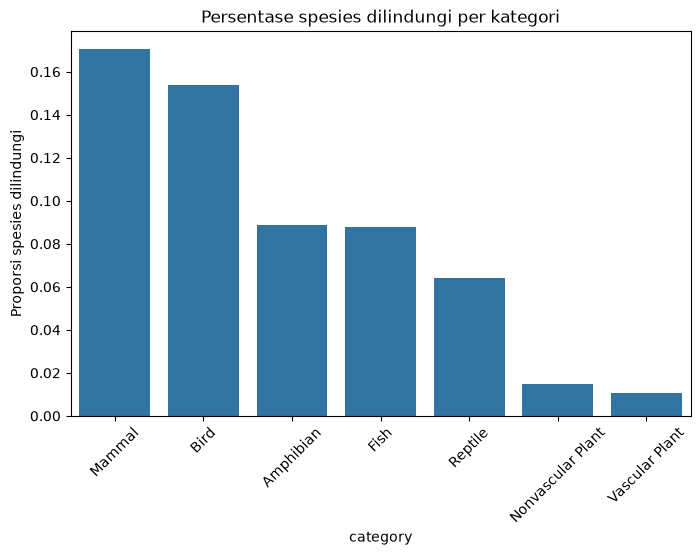

In [59]:
prop_sorted = prop.sort_values("proportion", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=prop_sorted.index, y=prop_sorted["proportion"])
plt.xticks(rotation=45)
plt.ylabel("Proporsi spesies dilindungi")
plt.title("Persentase spesies dilindungi per kategori")
plt.show()


Dari grafik ini kelihatan bahwa mamalia dan burung paling banyak yang berstatus
dilindungi, masing-masing sekitar 17% dan 15%. Sebaliknya, kelompok tumbuhan
justru paling sedikit, cuma sekitar 1%. Kemungkinan karena hewan lebih cepat
terdampak perubahan lingkungan dibanding tumbuhan.


In [60]:
from scipy.stats import chi2_contingency

table = pd.crosstab(species.category, species.conservation_status)
chi2, p, dof, expected = chi2_contingency(table)
print("chi2 =", chi2)
print("p-value =", p)


chi2 = 628.581965798279
p-value = 2.4551423165990194e-117


Nilai p di bawah 0.05, jadi bisa disimpulkan kategori spesies memang berhubungan
secara signifikan dengan status konservasinya. Jadi pola yang tadi terlihat bukan
sekadar kebetulan.


## 3. Observasi per Taman


In [61]:
merged = observations.merge(species, on="scientific_name")
merged.head()


,scientific_name,park_name,observations,category,common_names,conservation_status
0,Vicia benghalensis,Great Smoky Mountains National Park,68,Vascular Plant,"Purple Vetch, Reddish Tufted Vetch",No Intervention
1,Neovison vison,Great Smoky Mountains National Park,77,Mammal,American Mink,No Intervention
2,Prunus subcordata,Yosemite National Park,138,Vascular Plant,Klamath Plum,No Intervention
3,Abutilon theophrasti,Bryce National Park,84,Vascular Plant,Velvetleaf,No Intervention
4,Githopsis specularioides,Great Smoky Mountains National Park,85,Vascular Plant,Common Bluecup,No Intervention


In [62]:
merged.groupby("park_name").observations.sum().sort_values(ascending=False)


park_name
Yellowstone National Park              1587641
Yosemite National Park                  949452
Bryce National Park                     633291
Great Smoky Mountains National Park     474863
Name: observations, dtype: int64

In [63]:
merged.sort_values("observations", ascending=False)[["park_name", "common_names", "observations"]].head(10)


,park_name,common_names,observations
12447,Yellowstone National Park,"Deep-Root Clubmoss, Ground Cedar",321
1299,Yellowstone National Park,"Giant Red Indian Paintbrush, Great Red Indian ...",317
9637,Yellowstone National Park,American Dragonhead,316
22819,Yellowstone National Park,"Fendler's Cryptantha, Sanddune Catseye, Sanddu...",316
7823,Yellowstone National Park,"Threelobe Beggarticks, Three-Lobe Beggarticks",314
7822,Yellowstone National Park,"Stick-Tight, Three-Lobe Beggar-Ticks",314
1937,Yellowstone National Park,"Great Bulrush, Softstem Bulrush, Soft-Stem Bul...",312
4284,Yellowstone National Park,"Greek Valerian, Greek Valerian, Jacob's Ladder",312
25546,Yellowstone National Park,"Marsh Primrose-Willow, Marsh Seedbox",310
25545,Yellowstone National Park,Water Purslane,310


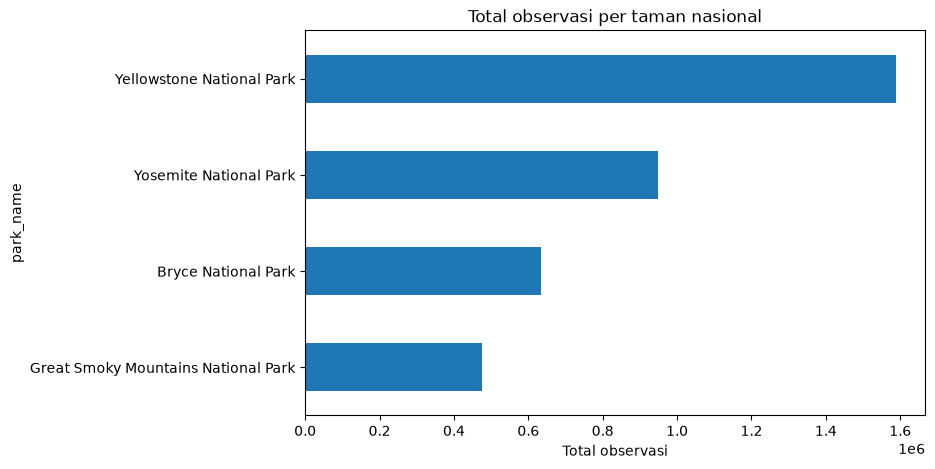

In [64]:
park_totals = merged.groupby("park_name").observations.sum().sort_values()

plt.figure(figsize=(8, 5))
park_totals.plot(kind="barh")
plt.xlabel("Total observasi")
plt.title("Total observasi per taman nasional")
plt.show()


## 4. Kesimpulan


1. Sebagian besar spesies tidak masuk program konservasi; yang masuk paling banyak
   berstatus "Species of Concern".
2. Kelompok mamalia dan burung punya proporsi dilindungi paling tinggi, sedangkan
   tumbuhan paling rendah.
3. Uji chi-square menunjukkan hubungan yang signifikan antara kategori spesies dan
   status konservasi (p < 0.05).
4. Taman Yellowstone mencatat total observasi paling banyak dibanding taman lain.
5. Saran: upaya konservasi bisa difokuskan pada mamalia dan burung, dan pemantauan
   perlu ditambah di taman dengan jumlah observasi paling sedikit.
